# Quality, sensitivity and interpretation

Separate model acceptance from accuracy and inspect whether a requested detail level was actually used.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

This notebook compares requested per-storey and perimeter/core zoning under matched physical inputs. Diagnostics identify the effective mode and any substitution; energy arrays then describe the accepted result. “Accepted” means the declared engine/output checks passed, not that the building has been calibrated against observations.

Read the existing zoning-sensitivity figure as an example of reporting matched differences across shapes and climates. Its retained runs have their own assumptions and provenance. The curves and bars below are a separate small experiment, so exact agreement with that documentation figure is not a notebook acceptance criterion.

### Figure guide — Retained example: zoning differences across shapes and climates

![Retained example: zoning differences across shapes and climates; reference figure from EPSM documentation](../../docs/figures/zoning-sensitivity.svg)

**How to read this figure.** Compare per-storey with perimeter/core while holding each case’s other inputs fixed. Read the actual units: absolute differences remain useful when baseline cooling is near zero. This separate documentation experiment cannot establish that finer zoning is unnecessary for every building or use.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/zoning-sensitivity.svg).*

The [retained experiment data](../../docs/figures/geometry-sensitivity-data.json) records run identities, climate files and assumptions for this reference figure.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Compare matched zoning modes

Both cases preserve geometry and operations. Any substitution invalidates a claim about the requested zoning mode unless reported separately.

### Read the code and output

The effective-mode and substitution assertions protect the meaning of the comparison. If a requested perimeter/core case fell back to per-storey, labelling its result perimeter/core would conceal the failure and bias the study. Keep both requested and achieved modelling detail in any exported table.

Reference: [The same forms under different thermal partitions](../../docs/figures/geometry-zoning.svg). This linked documentation illustration is separate from the outputs computed below.

,requested,effective,accepted,heating_kwh,cooling_kwh
0,per_storey,per_storey,True,66263.288392,0.0
1,perimeter_core,perimeter_core,True,66264.035049,0.0


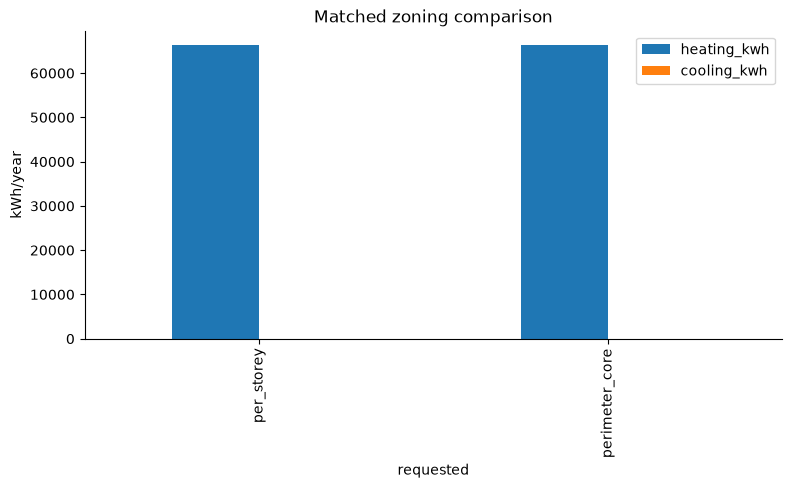

In [2]:
b=building(); results={}
for mode in ["per_storey","perimeter_core"]:
    spec=b.updated(geometry=b.geometry.updated(zoning=ZoningSpec(mode=mode,on_failure="error")))
    results[mode]=EnergyPlusRunner(engine()).run(spec,OUT/mode)
rows=[]
for mode,r in results.items():
    zoning=r.diagnostics["zoning"]
    assert zoning["effective_mode"]==mode and not zoning["substituted"]
    rows.append({"requested":mode,"effective":zoning["effective_mode"],"accepted":r.diagnostics["accepted"],"heating_kwh":r.scalars["space_heating_demand_kwh"],"cooling_kwh":r.scalars["cooling_demand_kwh"]})
frame=table(rows).set_index("requested")
fig, ax = plt.subplots(figsize=(9, 4))
frame[["heating_kwh","cooling_kwh"]].plot.bar(ax=ax, ylabel="kWh/year",title="Matched zoning comparison"); plt.show(); plt.close(fig)

## Inspect absolute differences

Percentages become unstable near zero cooling demand. Show absolute differences and a clearly defined baseline before reporting percentages.

### Read the code and output

Near-zero cooling makes relative percentages unstable or undefined. Absolute kWh differences remain interpretable, provided the baseline and subtraction direction are explicit. A small difference in these cases does not establish that zoning detail is irrelevant for all envelopes, schedules or local comfort questions.

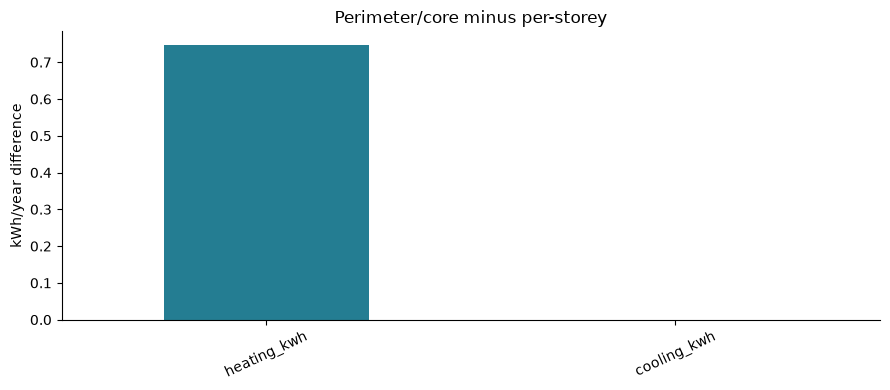

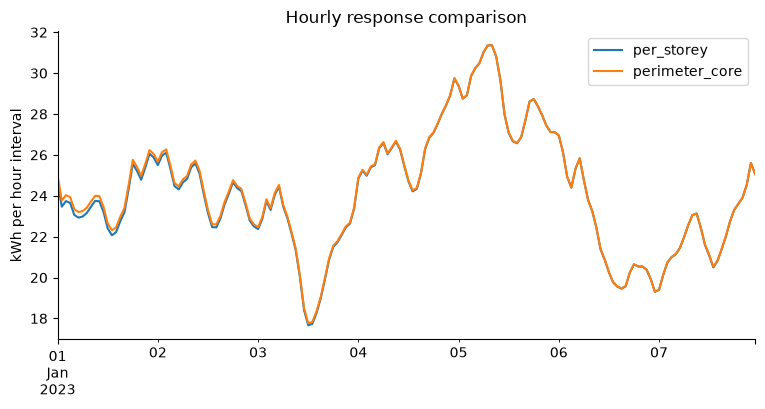

In [3]:
delta=frame.loc["perimeter_core",["heating_kwh","cooling_kwh"]]-frame.loc["per_storey",["heating_kwh","cooling_kwh"]]
bars(delta.to_dict(),"kWh/year difference","Perimeter/core minus per-storey")
profiles={mode:result_frame(r).space_heating_demand_kwh for mode,r in results.items()}
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame(profiles).iloc[:168].plot(ax=ax, ylabel="kWh per hour interval",title="Hourly response comparison"); plt.show(); plt.close(fig)

## Retain the interpretation evidence

An accepted model passes its declared checks; predictive accuracy requires independent observations. Preserve run IDs, climate identity and assumptions when sharing a comparison.

### Read the code and output

Run IDs and weather/input hashes let another analyst locate the exact experiment. The interpretation string correctly separates sensitivity from calibration. Add independent measured-energy evidence before making claims about predictive accuracy; the acceptance diagnostics alone cannot supply it.

In [4]:
evidence={"weather_sha256":b.climate.weather_sha256,"input_hash":b.physical_hash(),"runs":{name:r.run_id for name,r in results.items()},"interpretation":"Illustrative sensitivity only; no measured-energy calibration"}
(OUT/"comparison-evidence.json").write_text(json.dumps(evidence,indent=2))
table(evidence)
assert all(r.diagnostics["accepted"] for r in results.values())

,field,value
0,weather_sha256,99f6df726debe1f7df19317227ced9685fa3cf9d031bd5...
1,input_hash,f4719311c3a1bdf3951b730c9b161b33bc83cfadb087d3...
2,runs,{'per_storey': 'a6458f1aa204e03ad323116db75f16...
3,interpretation,Illustrative sensitivity only; no measured-ene...


## Interpretation and next experiment

Use sensitivity to prioritize uncertain inputs and modelling detail. It does not prove that one geometry or operations assumption is correct for an observed building.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.